In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import urllib.request
import zipfile

In [ ]:
URL = "https://api.insee.fr/melodi/file/DS_RP_EMPLOI_LR_COMP/DS_RP_EMPLOI_LR_COMP_2023_CSV_FR"
urllib.request.urlretrieve(URL, "emploi.zip")

with zipfile.ZipFile("emploi.zip") as z:
    with z.open("DS_RP_EMPLOI_LR_COMP_2023_data.csv") as f:
        emploi = pd.read_csv(f, sep=";", dtype={"GEO": str, "EMPSTA_ENQ": str})

KeyboardInterrupt: 

In [ ]:
emploi = emploi [['TIME_PERIOD','EMPSTA_ENQ','GEO','OBS_VALUE','PCS']]

emploi_dep = emploi.loc[emploi["PCS"] == "_T"] # on choisit de s'intéresser aux résultats agrégés par PCS.
# Si on veut une analyse plus fine, on pourra dans un second temps regarder par PCS...
emploi_dep = emploi_dep.reset_index(drop=True)
emploi_dep = emploi_dep.rename(columns={
    "TIME_PERIOD": "Annee",
    "EMPSTA_ENQ":"Statut",
    "GEO":"Code departement",
    "OBS_VALUE": "Population"
})

emploi_dep= emploi_dep.drop(columns=["PCS"])

emploi_dep.head(20)

,Annee,Statut,Code departement,Population
0,2012,1,001,5.684150e+06
1,2012,1T2,001,6.377119e+06
2,2012,2,001,6.929694e+05
3,2017,1,001,5.696479e+06
4,2017,1T2,001,6.407343e+06
5,2017,2,001,7.108635e+05
6,2023,1,001,5.997447e+06
7,2023,1T2,001,6.598552e+06
8,2023,2,001,6.011057e+05
9,2012,1,002,9.094996e+05


In [4]:
emploi_pivot = emploi_dep[emploi_dep['Code departement'].str.len() == 3]
emploi_pivot= emploi_pivot.pivot_table(
    index=['Annee', 'Code departement'],
    columns='Statut',
    values='Population').reset_index()

emploi_pivot.head(20)


Statut,Annee,Code departement,1,1T2,2
0,2012,001,5.684150e+06,6.377119e+06,692969.389410
1,2012,002,9.094996e+05,1.021020e+06,111520.659150
2,2012,003,6.850123e+05,7.922593e+05,107246.977690
3,2012,004,5.828589e+05,6.732480e+05,90389.106180
4,2012,005,5.833271e+05,6.553992e+05,72072.172470
5,2012,006,5.238807e+05,5.903065e+05,66425.825870
6,2012,008,4.030589e+05,4.481345e+05,45075.620400
7,2012,010,3.502405e+05,3.941662e+05,43925.765410
8,2012,011,5.005247e+04,5.536768e+04,5315.215620
9,2012,012,2.117370e+05,2.419748e+05,30237.769915


In [5]:
emploi_pivot["Taux d'activite"]=emploi_pivot["1"]/emploi_pivot['1T2']
emploi_pivot=emploi_pivot.drop(columns=["1","1T2","2"])
emploi_pivot.head()

Statut,Annee,Code departement,Taux d'activite
0,2012,001,0.891335
1,2012,002,0.890775
2,2012,003,0.864631
3,2012,004,0.865742
4,2012,005,0.890033


In [6]:
# base avec un taux de progression entre 2017 et 2023 du taux d'activité par département

emploi_prog_CT=emploi_pivot[["Code departement","Annee","Taux d'activite"]]

emploi_prog_CT=emploi_prog_CT.pivot_table(
    index=['Code departement'],
    columns='Annee',
    values="Taux d'activite").reset_index()

emploi_prog_CT["Progression 2023"]=emploi_prog_CT[2023]-emploi_prog_CT[2017]
emploi_prog_CT["Progression 2017"]=emploi_prog_CT[2017]-emploi_prog_CT[2012]

emploi_prog_CT.head(15)

Annee,Code departement,2012,2017,2023,Progression 2023,Progression 2017
0,001,0.891335,0.889055,0.908903,0.019849,-0.002280
1,002,0.890775,0.890444,0.914784,0.024340,-0.000331
2,003,0.864631,0.867962,0.906470,0.038509,0.003330
3,004,0.865742,0.861590,0.895545,0.033955,-0.004152
4,005,0.890033,0.885475,0.910001,0.024526,-0.004558
5,006,0.887472,0.880970,0.914439,0.033469,-0.006503
6,008,0.899415,0.896621,0.923513,0.026892,-0.002794
7,010,0.888560,0.885235,0.910268,0.025033,-0.003325
8,011,0.904001,0.899181,0.925007,0.025826,-0.004821
9,012,0.875038,0.872169,0.897273,0.025104,-0.002869


Préparation des données du bac à partir de ce site: 

In [13]:
URL = "https://data.education.gouv.fr/api/explore/v2.1/catalog/datasets/fr-en-indicateurs-de-resultat-des-lycees-denseignement-general-et-technologique/exports/csv?use_labels=true"
bac = pd.read_csv(URL,sep=";",low_memory=False)

bac.head()

,Etablissement,Annee,Ville,UAI,Code commune,Academie,Departement,Secteur,Presents - L,Presents - ES,...,Valeur ajoutée du taux de mentions - Gnle,Nombre de mentions TB avec félicitations - G,Nombre de mentions TB sans félicitations - G,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T,Libelle departement
0,LYCEE VICTOR BERARD (GENERAL ET TECHNO.),2023,MOREZ,0390027T,39368,BESANCON,JURA,public,NaN,NaN,...,-3,1.0,8.0,24.0,29.0,NaN,NaN,10.0,7.0,Jura
1,LYCEE VAL DE LOIRE (GENERAL ET TECHNO.),2023,BLOIS,0410899E,41018,ORLEANS-TOURS,LOIR-ET-CHER,public,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3.0,5.0,15.0,Loir-et-Cher
2,LYCEE JACOB HOLTZER,2023,FIRMINY,0420014M,42095,LYON,LOIRE,public,NaN,NaN,...,-17,NaN,6.0,10.0,19.0,NaN,NaN,1.0,8.0,Loire
3,LYCEE HONORE D'URFE,2023,SAINT ETIENNE,0420042T,42218,LYON,LOIRE,public,NaN,NaN,...,1,1.0,16.0,53.0,63.0,NaN,NaN,21.0,37.0,Loire
4,LYCEE JEAN MONNET,2023,SAINT ETIENNE,0420043U,42218,LYON,LOIRE,public,NaN,NaN,...,-5,NaN,8.0,10.0,31.0,NaN,NaN,10.0,20.0,Loire


In [16]:
bac=bac[["Annee","Code departement",
"Presents - Toutes series",
"Taux de reussite - Toutes series",
"Taux de mentions - Toutes series"]]

bac.head(10)

,Annee,Code departement,Presents - Toutes series,Taux de reussite - Toutes series,Taux de mentions - Toutes series
0,2023,39,120,98.0,66.0
1,2023,41,38,95.0,61.0
2,2023,42,99,96.0,44.0
3,2023,42,415,89.0,46.0
4,2023,42,160,92.0,49.0
5,2023,42,67,96.0,52.0
6,2023,43,135,96.0,63.0
7,2023,43,55,98.0,47.0
8,2023,44,271,99.0,77.0
9,2023,44,106,100.0,66.0


In [17]:
bac["reussites_poids"] = bac["Presents - Toutes series"]*bac["Taux de reussite - Toutes series"]/100
bac["mentions_poids"] = bac["Presents - Toutes series"]*bac["Taux de mentions - Toutes series"]/100
bac=bac[(bac["Annee"]==2012) | (bac["Annee"]==2017) | (bac["Annee"]==2023)]


bac= bac.groupby(["Code departement","Annee"]).agg({"Presents - Toutes series":"sum",
                                               "reussites_poids":"sum",
                                               "mentions_poids":"sum"})

bac["Taux de reussite"] = bac["reussites_poids"]/bac["Presents - Toutes series"]
bac["Taux de mentions"] = bac["mentions_poids"]/bac["Presents - Toutes series"]
bac=bac.reset_index()

bac.head(20)

,Code departement,Annee,Presents - Toutes series,reussites_poids,mentions_poids,Taux de reussite,Taux de mentions
0,01,2012,3628,3321.34,0.00,0.915474,0.000000
1,01,2017,4208,3806.90,2086.12,0.904682,0.495751
2,01,2023,4713,4467.15,2858.18,0.947836,0.606446
3,02,2012,3374,2826.09,0.00,0.837608,0.000000
4,02,2017,3545,3181.16,1612.08,0.897365,0.454748
5,02,2023,3388,3164.39,1853.15,0.933999,0.546975
6,03,2012,1733,1503.90,0.00,0.867802,0.000000
7,03,2017,1930,1759.04,988.64,0.911420,0.512249
8,03,2023,1951,1854.74,1090.70,0.950661,0.559047
9,04,2012,1040,941.61,0.00,0.905394,0.000000


In [18]:
# base avec un taux de progression entre 2017 et 2023

bac_prog_CT=bac[["Code departement","Annee","Taux de reussite"]]
bac_prog_CT=bac_prog_CT[(bac_prog_CT["Annee"]==2012)|(bac_prog_CT["Annee"]==2017)| (bac_prog_CT["Annee"]==2023)]

bac_prog_CT=bac_prog_CT.pivot_table(
    index=['Code departement'],
    columns='Annee',
    values='Taux de reussite').reset_index()

bac_prog_CT["Progression bac 2023"]=bac_prog_CT[2023]-bac_prog_CT[2017]
bac_prog_CT["Progression bac 2017"]=bac_prog_CT[2017]-bac_prog_CT[2012]

bac_prog_CT.head(15)

Annee,Code departement,2012,2017,2023,Progression bac 2023,Progression bac 2017
0,01,0.915474,0.904682,0.947836,0.043154,-0.010793
1,02,0.837608,0.897365,0.933999,0.036634,0.059757
2,03,0.867802,0.911420,0.950661,0.039242,0.043618
3,04,0.905394,0.927243,0.956622,0.029379,0.021848
4,05,0.902993,0.944278,0.978662,0.034384,0.041286
5,06,0.903189,0.910586,0.950297,0.039711,0.007397
6,07,0.915591,0.925238,0.955451,0.030212,0.009648
7,08,0.821302,0.873932,0.929232,0.055300,0.052630
8,09,0.852344,0.887636,0.962747,0.075111,0.035291
9,10,0.887620,0.897166,0.926589,0.029422,0.009547


In [12]:
emploi_prog_CT["Code departement"] = emploi_prog_CT["Code departement"].astype(str).str.zfill(3)

bac_prog_CT["Code departement"] = bac_prog_CT["Code departement"].astype(str).str.zfill(3)

bac_emploi_prog_CT = bac_prog_CT.merge(
    emploi_prog_CT,
    left_on = ["Code departement"],
  right_on = ["Code departement"],
  how = "left"
)



bac_emploi_prog_CT = bac_emploi_prog_CT.dropna()

bac_emploi_prog_CT.head(15)

Annee,Code departement,2012_x,2017_x,2023_x,Progression bac 2023,Progression bac 2017,2012_y,2017_y,2023_y,Progression 2023,Progression 2017
0,001,0.915474,0.904682,0.947836,0.043154,-0.010793,0.891335,0.889055,0.908903,0.019849,-0.002280
1,002,0.837608,0.897365,0.933999,0.036634,0.059757,0.890775,0.890444,0.914784,0.024340,-0.000331
2,003,0.867802,0.911420,0.950661,0.039242,0.043618,0.864631,0.867962,0.906470,0.038509,0.003330
3,004,0.905394,0.927243,0.956622,0.029379,0.021848,0.865742,0.861590,0.895545,0.033955,-0.004152
4,005,0.902993,0.944278,0.978662,0.034384,0.041286,0.890033,0.885475,0.910001,0.024526,-0.004558
5,006,0.903189,0.910586,0.950297,0.039711,0.007397,0.887472,0.880970,0.914439,0.033469,-0.006503
7,008,0.821302,0.873932,0.929232,0.055300,0.052630,0.899415,0.896621,0.923513,0.026892,-0.002794
9,010,0.887620,0.897166,0.926589,0.029422,0.009547,0.888560,0.885235,0.910268,0.025033,-0.003325
10,011,0.871185,0.892843,0.926097,0.033255,0.021658,0.904001,0.899181,0.925007,0.025826,-0.004821
11,012,0.924212,0.953353,0.980400,0.027048,0.029141,0.875038,0.872169,0.897273,0.025104,-0.002869


Text(0.5, 1.0, "Comparaison de la progression des taux d'activité et de réussite au baccalauréat par département entre 2017 et 2023")

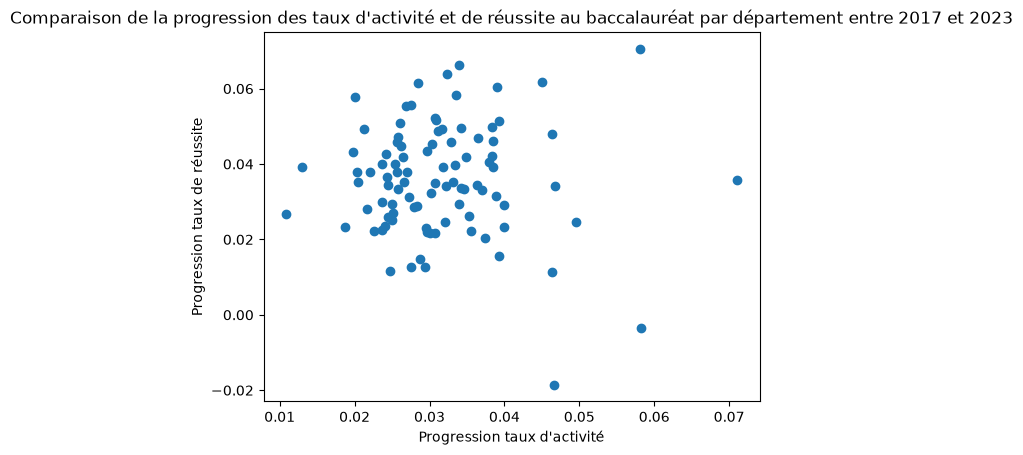

In [18]:
plt.scatter(bac_emploi_prog_CT["Progression 2023"],bac_emploi_prog_CT["Progression bac 2023"])
plt.xlabel("Progression taux d'activité")
plt.ylabel("Progression taux de réussite")
plt.title("Comparaison de la progression des taux d'activité et de réussite au baccalauréat par département entre 2017 et 2023")

conclusion: ce n'est pas très concluant...

Text(0.5, 1.0, "Comparaison de la progression des taux d'activité et de réussite au baccalauréat par département entre 2012 et 2017")

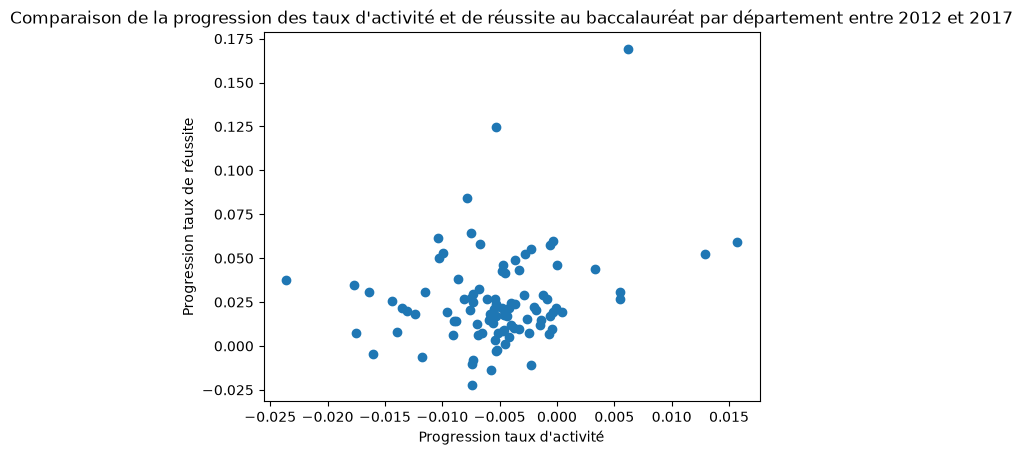

In [20]:
plt.scatter(bac_emploi_prog_CT["Progression 2017"],bac_emploi_prog_CT["Progression bac 2017"])
plt.xlabel("Progression taux d'activité")
plt.ylabel("Progression taux de réussite")
plt.title("Comparaison de la progression des taux d'activité et de réussite au baccalauréat par département entre 2012 et 2017")

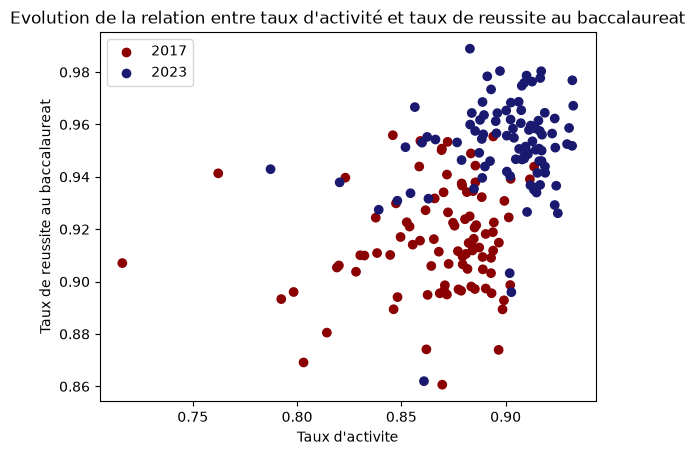

In [ ]:
couleurs_1= {'2017':'darkred', '2023':'midnightblue'}

emploi_filtre1 = emploi_pivot[emploi_pivot["Annee"].isin([2017, 2023])]
bac_filtre1 = bac[bac["Annee"].isin([2017, 2023])]

emploi_filtre1["Code departement"] = emploi_filtre1["Code departement"].astype(str).str.zfill(3)
bac_filtre1["Code departement"] = bac_filtre1["Code departement"].astype(str).str.zfill(3)

bac_emploi_filtre1 = emploi_filtre1.merge(
    bac_filtre1,
    on=["Annee","Code departement"],
    how="inner"
)

plt.scatter(bac_emploi_filtre1["Taux d'activite"],
    bac_emploi_filtre1["Taux de reussite"],
    c=bac_emploi_filtre1["Annee"].astype(str).map(couleurs_1)
)

plt.xlabel("Taux d'activite")
plt.ylabel("Taux de reussite au baccalaureat")
plt.scatter([], [], color='darkred', label='2017')
plt.scatter([], [], color='midnightblue', label='2023')

plt.legend()

plt.title("Evolution de la relation entre taux d'activité et taux de reussite au baccalaureat")

plt.show()


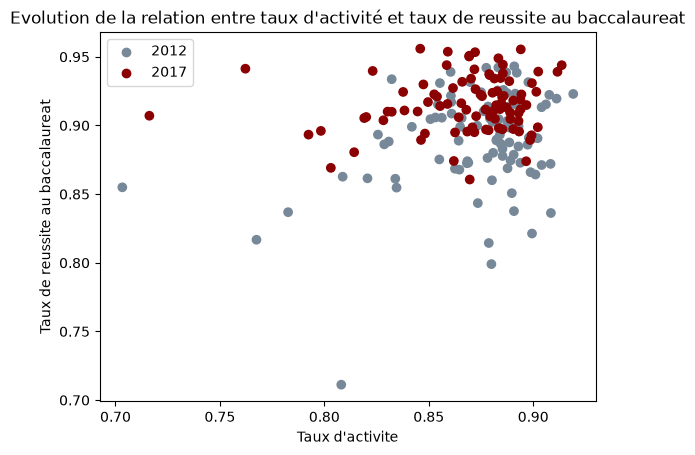

In [ ]:
couleurs_2= {'2012':'lightslategray', '2017':'darkred'}

emploi_filtre2 = emploi_pivot[emploi_pivot["Annee"].isin([2012, 2017])]
bac_filtre2 = bac[bac["Annee"].isin([2012, 2017])]

emploi_filtre2["Code departement"] = emploi_filtre2["Code departement"].astype(str).str.zfill(3)
bac_filtre2["Code departement"] = bac_filtre2["Code departement"].astype(str).str.zfill(3)

bac_emploi_filtre2 = emploi_filtre2.merge(
    bac_filtre2,
    on=["Annee","Code departement"],
    how="inner"
)

plt.scatter(bac_emploi_filtre2["Taux d'activite"],
    bac_emploi_filtre2["Taux de reussite"],
    c=bac_emploi_filtre2["Annee"].astype(str).map(couleurs_2)
)

plt.xlabel("Taux d'activite")
plt.ylabel("Taux de reussite au baccalaureat")
plt.scatter([], [], color='lightslategray', label='2012')
plt.scatter([], [], color='darkred', label='2017')

plt.legend()

plt.title("Evolution de la relation entre taux d'activité et taux de reussite au baccalaureat")

plt.show()


On veut désormais faire un graphique avec des flèches pour rendre plus lisible les évolutions

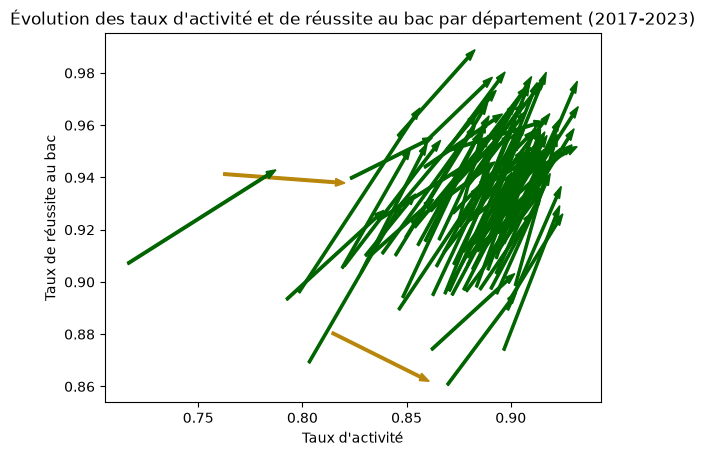

In [24]:
bac_emploi_dep1=bac_emploi_filtre1.pivot(
    index="Code departement",
    columns="Annee",
    values=["Taux d'activite", "Taux de reussite"]
)

for departement in bac_emploi_dep1.index:

    x1 = bac_emploi_dep1.loc[departement, ("Taux d'activite", 2017)]
    y1 = bac_emploi_dep1.loc[departement, ("Taux de reussite", 2017)]

    x2 = bac_emploi_dep1.loc[departement, ("Taux d'activite", 2023)]
    y2 = bac_emploi_dep1.loc[departement, ("Taux de reussite", 2023)]

    if x2>x1 and y2>y1:
        couleur="darkgreen"
    
    elif x1>x2 and y1>y2:
        couleur="darkred"
    
    else:
        couleur="darkgoldenrod"

    plt.arrow(
        x1, y1,
        x2-x1, y2-y1,
        color=couleur,
        length_includes_head=True
    )

plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite au bac")
plt.title("Évolution des taux d'activité et de réussite au bac par département (2017-2023)")

plt.show()

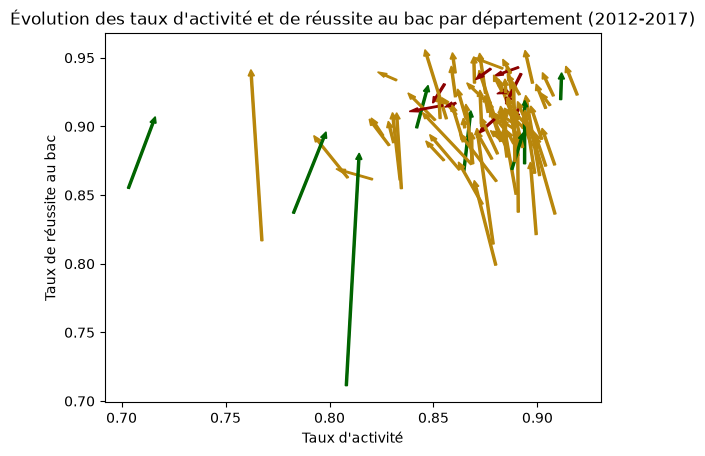

In [25]:
bac_emploi_dep2=bac_emploi_filtre2.pivot(
    index="Code departement",
    columns="Annee",
    values=["Taux d'activite", "Taux de reussite"]
)

for departement in bac_emploi_dep2.index:

    x1 = bac_emploi_dep2.loc[departement, ("Taux d'activite", 2012)]
    y1 = bac_emploi_dep2.loc[departement, ("Taux de reussite", 2012)]

    x2 = bac_emploi_dep2.loc[departement, ("Taux d'activite", 2017)]
    y2 = bac_emploi_dep2.loc[departement, ("Taux de reussite", 2017)]

    if x2>x1 and y2>y1:
        couleur="darkgreen"
    
    elif x1>x2 and y1>y2:
        couleur="darkred"
    
    else:
        couleur="darkgoldenrod"

    plt.arrow(
        x1, y1,
        x2-x1, y2-y1,
        color=couleur,
        length_includes_head=True
    )

plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite au bac")
plt.title("Évolution des taux d'activité et de réussite au bac par département (2012-2017)")

plt.show()

Remarque: cela est intéressant pour montrer que l'existence de la corrélation est tout sauf assurée: si corrélation forte il y avait, on devrait surtout avoir des fleches vertes et rouges...